## Using observations to check 30-year modulations of ENSO impacts

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [4]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [5]:
import cmocean
from scipy import stats

In [6]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [7]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [8]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [9]:
import regionmask

In [10]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.land

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [11]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [12]:
import sys

In [13]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [14]:
from functions import preproc_funcs as funcs


### import data

In [15]:
ersst = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/tos_ersstv5_g025_185401-202412.nc')
ersst['time'] = xr.cftime_range('1854-01-01', '2025-01-01', freq='1M')

hadisst = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/tos_hadisst_g025_187001-202412.nc')
hadisst['time'] = xr.cftime_range('1870-01-01', '2025-01-01', freq='1M')

In [16]:
ersst_det = funcs.detrend_rolling_window(funcs.calc_anom(ersst, ersst.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
hadisst_det = funcs.detrend_rolling_window(funcs.calc_anom(hadisst, hadisst.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)

In [17]:
tas_obs = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/tas_hadcrut.5.0.2.0_g025_185001-202402.nc')
tas_obs['time'] = xr.cftime_range('1850-01-01', '2024-03-01', freq='1M')
pr_obs = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/pr_gpcc.10.v2022_g025_189101-202402.nc')
pr_obs['time'] = xr.cftime_range('1891-01-01', '2024-03-01', freq='1M')

In [18]:
# pr_era5 = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/pr_era5_g025_194001-202312.nc')
# pr_era5['time'] = xr.cftime_range('1940-01-01', '2024-01-01', freq='1M')

In [19]:
pr_rean = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/precip/prate.mon.mean.nc')
pr_rean = pr_rean.rename(dict(prate = 'pr'))
pr_rean['time'] = xr.cftime_range('1836-01-01', '2016-01-01', freq='1M')
pr_rean

<xarray.Dataset> Size: 563MB
Dimensions:    (lat: 181, lon: 360, time: 2160, nbnds: 2)
Coordinates:
  * lat        (lat) float32 724B -90.0 -89.0 -88.0 -87.0 ... 88.0 89.0 90.0
  * lon        (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * time       (time) object 17kB 1836-01-31 00:00:00 ... 2015-12-31 00:00:00
Dimensions without coordinates: nbnds
Data variables:
    time_bnds  (time, nbnds) float64 35kB dask.array<chunksize=(1, 2), meta=np.ndarray>
    pr         (time, lat, lon) float32 563MB dask.array<chunksize=(1, 181, 360), meta=np.ndarray>
Attributes: (12/24)
    Conventions:               CF-1.2
    title:                     Monthly NOAA/CIRES/DOE 20th Century Reanalysis V3
    comments:                  Data are from \nNOAA/CIRES/DOE 20th Century Re...
    standard_name_vocabulary:  NetCDF Climate and Forecast (CF) Metadata Conv...
    license:                   These data are available free of charge under ...
    spatial_resolution:        1.0 degree
    ...                        ...
    citation1:                 Slivinski, L. C, G. P. Compo, J. S. Whitaker, ...
    References:                https://www.psl.noaa.gov/data/gridded/data.20t...
    creator_name:              NOAA/PSL
    institution:               NOAA Physical Sciences Laboratory & CU/CIRES \...
    contact:                   psl.data@noaa.gov
    citation:                  Compo,G.P. <https://www.psl.noaa.gov/people/gi...

In [20]:
tas_obs = funcs.calc_anom(tas_obs, tas_obs.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time')
pr_obs = funcs.calc_anom(pr_obs, pr_obs.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time')
pr_rean = funcs.calc_anom(pr_rean, pr_rean.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time')

In [21]:
# tas_obs.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/tas_obs.nc')
# pr_obs.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/pr_obs.nc')
# pr_rean.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/pr_rean.nc')

In [22]:
# test = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/smiles/ACCESS-ESM1-5_ts.nc')

In [23]:
tas_obs_det = funcs.detrend_rolling_window(tas_obs, window_size=15)
pr_obs_det = funcs.detrend_rolling_window(pr_obs, window_size=15)
pr_rean_det = funcs.detrend_rolling_window(pr_rean, window_size=15)

In [24]:
# psl = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/slp/prmsl.mon.mean.nc')
# psl = psl.rename(dict(prmsl = 'psl'))
# uwnd = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/wind/uwnd.10m.mon.mean.nc')
# vwnd = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/wind/vwnd.10m.mon.mean.nc')
# hgt = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/hgt/hgt.mon.mean_500.nc')

In [25]:
# psl_det = funcs.detrend_rolling_window(funcs.calc_anom(psl, psl.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
# uwnd_det = funcs.detrend_rolling_window(funcs.calc_anom(uwnd, uwnd.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
# vwnd_det = funcs.detrend_rolling_window(funcs.calc_anom(vwnd, vwnd.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
# hgt_det = funcs.detrend_rolling_window(funcs.calc_anom(hgt, hgt.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)

In [26]:
from dask.diagnostics import ProgressBar

In [27]:
with ProgressBar():
    ersst_det = ersst_det.tos.sel(time = slice('1900', '2014')).compute()
    hadisst_det = hadisst_det.tos.sel(time = slice('1900', '2014')).compute()
    tas_obs_det = tas_obs_det.tas.sel(time = slice('1900', '2014')).compute()
    pr_obs_det = pr_obs_det.pr.sel(time = slice('1900', '2014')).compute()
    pr_rean_det = pr_rean_det.pr.sel(time = slice('1900', '2014')).compute()

[########################################] | 100% Completed | 2.72 ss
[########################################] | 100% Completed | 2.86 ss
[########################################] | 100% Completed | 14.29 s
[########################################] | 100% Completed | 3.26 ss
[########################################] | 100% Completed | 16.84 s


In [31]:
# with ProgressBar():
#     psl_det = psl_det.psl.sel(time = slice('1900', '2014')).compute()
#     psl_det['time'] = pr_rean_det['time']
#     uwnd_det = uwnd_det.uwnd.sel(time = slice('1900', '2014')).compute()
#     uwnd_det['time'] = pr_rean_det['time']
#     vwnd_det = vwnd_det.vwnd.sel(time = slice('1900', '2014')).compute()
#     vwnd_det['time'] = pr_rean_det['time']
#     hgt_det = hgt_det.hgt.sel(time = slice('1900', '2014')).compute()
#     hgt_det['time'] = pr_rean_det['time']

In [36]:
pr_obs_std = pr_obs_det/pr_obs_det.std('time')
pr_rean_std = pr_rean_det/pr_rean_det.std('time')

In [37]:
pr_rean_std

<xarray.DataArray 'pr' (time: 115, lat: 181, lon: 360)> Size: 30MB
array([[[-0.282475  , -0.282475  , -0.282475  , ..., -0.282475  ,
         -0.282475  , -0.282475  ],
        [-0.15668504, -0.1503599 , -0.15630943, ..., -0.15972652,
         -0.15769635, -0.16777836],
        [-0.09038914, -0.09151712, -0.10576872, ..., -0.10767967,
         -0.11111484, -0.11233626],
        ...,
        [-0.10875204, -0.10709496, -0.11047538, ..., -0.10061551,
         -0.10568786, -0.11109946],
        [-0.20355771, -0.20261464, -0.19958377, ..., -0.19613436,
         -0.196644  , -0.19912545],
        [-0.24701141, -0.24701141, -0.24701141, ..., -0.24701141,
         -0.24701141, -0.24701141]],

       [[ 0.46080938,  0.46080938,  0.46080938, ...,  0.46080938,
          0.46080938,  0.46080938],
        [ 0.29817778,  0.3030413 ,  0.29455674, ...,  0.3074457 ,
          0.29914653,  0.30102062],
        [ 0.20668687,  0.21374084,  0.21157905, ...,  0.20880651,
          0.19600268,  0.20147993],
...
        [ 1.1457093 ,  1.1565455 ,  1.1787276 , ...,  1.0796652 ,
          1.1130645 ,  1.133194  ],
        [ 1.4977162 ,  1.5019453 ,  1.5047183 , ...,  1.4705197 ,
          1.4831054 ,  1.4861927 ],
        [ 1.7810166 ,  1.7810166 ,  1.7810166 , ...,  1.7810166 ,
          1.7810166 ,  1.7810166 ]],

       [[ 1.4870056 ,  1.4870056 ,  1.4870056 , ...,  1.4870056 ,
          1.4870056 ,  1.4870056 ],
        [ 1.2146847 ,  1.2215707 ,  1.2251503 , ...,  1.1953635 ,
          1.1907067 ,  1.2052119 ],
        [ 0.5425624 ,  0.54095423,  0.5724486 , ...,  0.515634  ,
          0.5244506 ,  0.5368324 ],
        ...,
        [ 2.4275744 ,  2.4337482 ,  2.4324756 , ...,  2.424981  ,
          2.4348595 ,  2.4265525 ],
        [ 2.412509  ,  2.4166374 ,  2.415178  , ...,  2.4056249 ,
          2.413907  ,  2.4092274 ],
        [ 1.7210498 ,  1.7210498 ,  1.7210498 , ...,  1.7210498 ,
          1.7210498 ,  1.7210498 ]]], dtype=float32)
Coordinates:
  * lat      (lat) float32 724B -90.0 -89.0 -88.0 -87.0 ... 87.0 88.0 89.0 90.0
  * lon      (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * time     (time) object 920B 1900-06-01 00:00:00 ... 2014-06-01 00:00:00

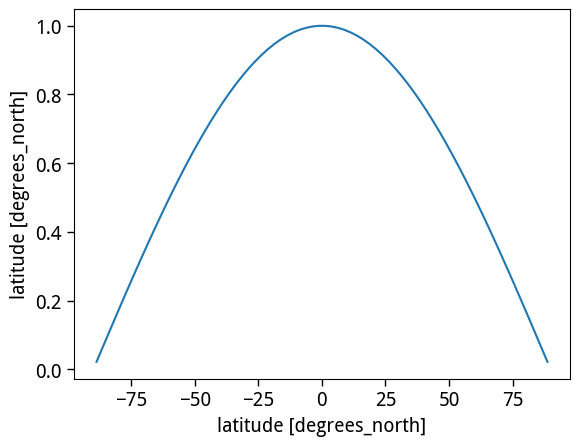

In [38]:
weights_obs = np.cos(np.deg2rad(hadisst_det.lat))
weights_obs.name = 'weights'
weights_obs.plot()

In [39]:
nino34_index_hadisst = hadisst_det.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_obs).mean(('lat', 'lon'))
nino34_index = nino34_index_hadisst
nino34_index_ersst = ersst_det.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_obs).mean(('lat', 'lon'))

In [40]:
# nino34_index_hadisst.to_dataset(name = 'tos').to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/nino34_index_hadisst.nc')

In [37]:
import seaborn as sns

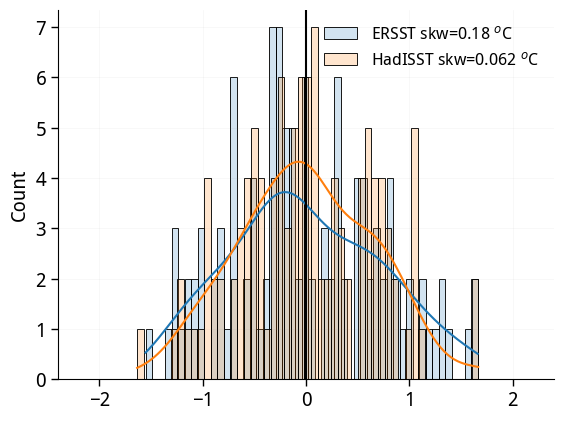

In [38]:
skw = stats.skew(nino34_index_ersst.dropna('time'))
sns.histplot(nino34_index_ersst, bins=51, kde=True, alpha=0.2, color='tab:blue', label=f'ERSST skw={np.round(skw, 3)} $^o$C')
skw = stats.skew(nino34_index_hadisst.dropna('time'))
sns.histplot(nino34_index_hadisst, bins=51, kde=True, alpha=0.2, color='tab:orange', label=f'HadISST skw={np.round(skw, 3)} $^o$C')
plt.axvline(0.0, color='k', ls='-')
plt.xlim(-2.4, 2.4)
# plt.title('Distribution of observed Nino3.4 SST anomalies')
plt.legend(frameon=False, fontsize=12)
plot_decorator()

In [32]:
a = hadisst_det.where(nino34_index_hadisst > nino34_index_hadisst.std('time'), drop=True).mean('time')
b = ersst_det.where(nino34_index_ersst > nino34_index_ersst.std('time'), drop=True).mean('time')
c = hadisst_det.where(nino34_index_hadisst < -nino34_index_hadisst.std('time'), drop=True).mean('time')
d = ersst_det.where(nino34_index_ersst < -nino34_index_ersst.std('time'), drop=True).mean('time')

plot_list = [
    a, b, a-b,
    c, d, c-d,
]

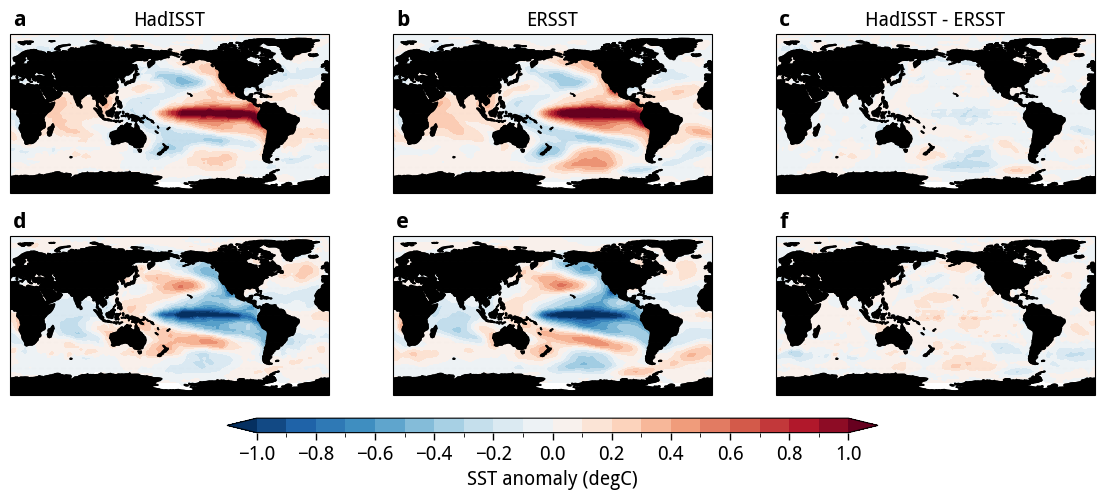

In [49]:
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
title_list = ['HadISST', 'ERSST',  'HadISST - ERSST',
              '', '', '']
label_list = ['a', 'b', 'c',
              'd', 'e', 'f']

plot_maps(xx, yy, plot_list, titles=title_list, labels=label_list, cmap='RdBu_r', levels=np.linspace(-1.0, 1.0, 21), pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=2, ncols=3, figsize=(14,6), land_mask_list = np.arange(0,6,1), add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=180), 
            cbar_kwargs=dict(orientation='horizontal', label='SST anomaly (degC)', aspect=45, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, auto_aspect=False)

In [36]:
nino34_index_hadisst

<xarray.DataArray 'tos' (time: 115)> Size: 920B
array([ 3.79403770e-01, -2.85343644e-01,  1.02079673e+00, -5.35260475e-01,
        6.56875417e-01,  8.70756882e-01, -4.88899244e-01, -3.18504419e-01,
       -5.50287830e-01, -9.62984059e-01, -6.67872578e-01,  5.08983025e-01,
       -4.75019477e-02,  5.13842238e-01,  7.17482341e-01,  1.07992321e-01,
       -9.70002403e-01, -2.61844406e-01,  7.67899633e-01,  3.18672084e-01,
       -1.47053331e-01, -2.50767267e-01, -4.55446357e-01,  2.86950577e-01,
       -8.05662585e-01,  8.15121412e-01, -3.12330310e-02,  2.56468298e-02,
       -1.20394453e-01,  2.60480206e-01,  1.04524955e+00,  3.40651037e-02,
       -1.40451454e-01, -8.99789924e-01, -4.13689856e-01,  6.32465531e-02,
       -3.53777224e-02,  7.42851474e-04, -5.69084657e-01,  6.02261492e-01,
        1.03365270e+00,  7.79491527e-01, -8.65576318e-01,  1.74428151e-02,
       -1.75105684e-01, -4.00008557e-01,  3.41757979e-02,  7.21054008e-02,
        2.28720302e-01, -5.19330780e-01, -5.24995852e-01,  6.98051961e-01,
        1.70453572e-01,  3.61685307e-01, -6.95389939e-01, -9.40015577e-01,
       -2.53935861e-01,  1.03782353e+00,  2.42380970e-01, -3.43420939e-02,
        7.22680571e-02, -1.88792741e-01, -2.29113593e-01,  4.28615949e-01,
       -6.08025524e-01,  9.78918245e-01, -1.24926122e-01, -2.96024960e-01,
        7.12212223e-01,  5.65630432e-01, -8.36638379e-01, -3.31531098e-01,
        1.14312044e+00, -1.26056825e+00, -4.62374552e-01, -1.15145782e+00,
        5.04821249e-01,  5.82271756e-01, -3.68883059e-02,  3.29459732e-01,
        9.46772863e-03,  6.20731223e-02,  1.64532144e+00, -5.48254391e-01,
       -9.28675034e-01, -6.29082656e-01,  6.77633937e-01,  6.43708253e-01,
       -1.63508232e+00, -2.29127157e-01,  1.07756189e-01,  1.02328910e+00,
        2.10946126e-01,  1.36269332e-01,  6.20672658e-01, -4.48862367e-01,
       -2.13247857e-01,  1.66565506e+00, -1.11167866e+00, -1.19372401e+00,
       -5.27685084e-01, -2.10543861e-02,  7.47943950e-01,  2.58576458e-01,
        6.07245343e-01, -8.30191114e-02,  5.28057945e-01, -9.91326341e-01,
       -4.77489475e-01,  8.35084879e-01, -1.19254000e+00, -6.33675201e-01,
        5.52180566e-02, -1.22833486e-01,  6.44390741e-01])
Coordinates:
  * time     (time) object 920B 1900-06-01 00:00:00 ... 2014-06-01 00:00:00

In [51]:
tas_regr = funcs.get_regr(nino34_index_hadisst.sel(time = slice('1950', '2014')).ffill('time').bfill('time'), tas_obs_det.sel(time = slice('1950', '2014')).ffill('time').bfill('time'), dim='time')
pr_regr = funcs.get_regr(nino34_index_hadisst.sel(time = slice('1950', '2014')).ffill('time').bfill('time'), pr_obs_std.sel(time = slice('1950', '2014')).ffill('time').bfill('time'), dim='time')
pr_regr_rean = funcs.get_regr(nino34_index_hadisst.sel(time = slice('1950', '2014')).ffill('time').bfill('time'), pr_rean_std.sel(time = slice('1950', '2014')).ffill('time').bfill('time'), dim='time')

In [52]:
tas_pval = funcs.get_pval(nino34_index_hadisst.sel(time = slice('1950', '2014')).ffill('time').bfill('time'), tas_obs_det.sel(time = slice('1950', '2014')).ffill('time').bfill('time'), dim='time')
pr_pval = funcs.get_pval(nino34_index_hadisst.sel(time = slice('1950', '2014')).ffill('time').bfill('time'), pr_obs_std.sel(time = slice('1950', '2014')).ffill('time').bfill('time'), dim='time')
pr_pval_rean = funcs.get_pval(nino34_index_hadisst.sel(time = slice('1950', '2014')).ffill('time').bfill('time'), pr_rean_std.sel(time = slice('1950', '2014')).ffill('time').bfill('time'), dim='time')

In [53]:
tas_pval

<xarray.DataArray (lat: 72, lon: 144)> Size: 83kB
array([[0.86691403, 0.86691403, 0.79038295, ..., 0.87019152, 0.866641  ,
        0.866641  ],
       [0.86691403, 0.86691403, 0.79038295, ..., 0.87019152, 0.866641  ,
        0.866641  ],
       [0.24059169, 0.24059169, 0.26242108, ..., 0.28113162, 0.28034785,
        0.28034785],
       ...,
       [0.42944897, 0.42944897, 0.36593982, ..., 0.53813309, 0.52221109,
        0.52221109],
       [0.16917564, 0.16917564, 0.14551421, ..., 0.21092246, 0.21389154,
        0.21389154],
       [0.16917564, 0.16917564, 0.14551421, ..., 0.21092246, 0.21389154,
        0.21389154]])
Coordinates:
  * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
  * lat      (lat) float64 576B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75

In [ ]:
plot_list = [
    tas_regr,
    tas_obs_det.where(nino34_index_hadisst > nino34_index_hadisst.std('time'), drop=True).mean('time'),
    tas_obs_det.where(nino34_index_hadisst < -nino34_index_hadisst.std('time'), drop=True).mean('time')
]

In [37]:
cond_nino = nino34_index_hadisst > nino34_index_hadisst.sel(time = slice('1950', '2015')).std('time')
cond_nina = nino34_index_hadisst < -nino34_index_hadisst.sel(time = slice('1950', '2015')).std('time')
cond_neut = (nino34_index_hadisst > -0.5*nino34_index_hadisst.sel(time = slice('1950', '2015')).std('time')) & (nino34_index_hadisst < 0.5*nino34_index_hadisst.sel(time = slice('1950', '2015')).std('time'))

# pval_list = [
#     tas_pval,
#     funcs.mannwhitneyu3d(tas_obs_det.where(cond_nino, drop=True), tas_obs_det.where(cond_neut, drop=True), dim='time'),
#     funcs.mannwhitneyu3d(tas_obs_det.where(cond_nina, drop=True), tas_obs_det.where(cond_neut, drop=True), dim='time'),
# ]

In [ ]:
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
title_list = [
    r'$T \sim \text{N}3.4$',
    r'$T$ (EN)',
    r'$T$ (LN)',
]
label_list = ['a', 'b', 'c']

plot_maps(xx, yy, plot_list, titles=title_list, labels=label_list, cmap='RdBu_r', levels=np.linspace(-1.0, 1.0, 21), pval = pval_list, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(14,5), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
            cbar_kwargs=dict(orientation='horizontal', label='degC/degC | degC', aspect=45, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, auto_aspect=False, draw_ipcc_regions=True)

In [38]:
### tas compostites

tas_en   = tas_obs_det.where(cond_nino)
tas_ln   = tas_obs_det.where(cond_nina)
tas_neut = tas_obs_det.where(cond_neut)

In [39]:
# pr_obs_en.to_netcdf("/g/data/if69/as8561/data/enso_tele_robustness/pr_obs_comp_en.nc")
# pr_obs_ln.to_netcdf("/g/data/if69/as8561/data/enso_tele_robustness/pr_obs_comp_ln.nc")
# pr_obs_neut.to_netcdf("/g/data/if69/as8561/data/enso_tele_robustness/pr_obs_comp_neut.nc")

In [ ]:
xr.Dataset(dict(en=tas_en, ln=tas_ln, neut=tas_neut)).to_netcdf("/g/data/if69/as8561/data/enso_tele_robustness/tas_composites.nc")

In [ ]:
plot_list = [
    pr_regr,
    pr_obs_std.where(nino34_index_hadisst > nino34_index_hadisst.std('time'), drop=True).mean('time'),
    pr_obs_std.where(nino34_index_hadisst < -nino34_index_hadisst.std('time'), drop=True).mean('time')
]

In [41]:
cond_nino = nino34_index_hadisst > nino34_index_hadisst.sel(time = slice('1950', '2015')).std('time')
cond_nina = nino34_index_hadisst < -nino34_index_hadisst.sel(time = slice('1950', '2015')).std('time')
cond_neut = (nino34_index_hadisst > -0.5*nino34_index_hadisst.sel(time = slice('1950', '2015')).std('time')) & (nino34_index_hadisst < 0.5*nino34_index_hadisst.sel(time = slice('1950', '2015')).std('time'))

# pval_list = [
#     pr_pval,
#     funcs.mannwhitneyu3d(pr_obs_std.where(cond_nino, drop=True), pr_obs_std.where(cond_neut, drop=True), dim='time'),
#     funcs.mannwhitneyu3d(pr_obs_std.where(cond_nina, drop=True), pr_obs_std.where(cond_neut, drop=True), dim='time'),
# ]

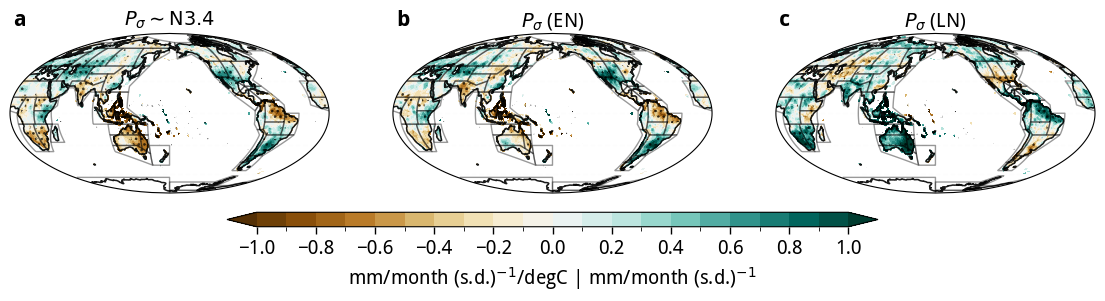

In [ ]:
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
title_list = [
    r'$P_{\sigma} \sim \text{N}3.4$',
    r'$P_{\sigma}$ (EN)',
    r'$P_{\sigma}$ (LN)',
]
label_list = ['a', 'b', 'c']

plot_maps(xx, yy, plot_list, titles=title_list, labels=label_list, cmap='BrBG', levels=np.linspace(-1.0, 1.0, 21), pval = pval_list, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(14,5), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
            cbar_kwargs=dict(orientation='horizontal', label='mm/month (s.d.)$^{-1}$/degC | mm/month (s.d.)$^{-1}$', aspect=45, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, auto_aspect=False, draw_ipcc_regions=True)

In [42]:
### pr_obs compostites

pr_obs_en   = pr_obs_std.where(cond_nino)
pr_obs_ln   = pr_obs_std.where(cond_nina)
pr_obs_neut = pr_obs_std.where(cond_neut)

In [43]:
# pr_obs_en.to_netcdf("/g/data/if69/as8561/data/enso_tele_robustness/pr_obs_comp_en.nc")
# pr_obs_ln.to_netcdf("/g/data/if69/as8561/data/enso_tele_robustness/pr_obs_comp_ln.nc")
# pr_obs_neut.to_netcdf("/g/data/if69/as8561/data/enso_tele_robustness/pr_obs_comp_neut.nc")

In [44]:
xr.Dataset(dict(en=pr_obs_en, ln=pr_obs_ln, neut=pr_obs_neut)).to_netcdf("/g/data/if69/as8561/data/enso_tele_robustness/pr_obs_composites.nc")

In [ ]:
plot_list = [
    pr_regr_rean,
    pr_rean_std.where(nino34_index_hadisst > nino34_index_hadisst.std('time'), drop=True).mean('time'),
    pr_rean_std.where(nino34_index_hadisst < -nino34_index_hadisst.std('time'), drop=True).mean('time')
]

In [46]:
cond_nino = nino34_index_hadisst > nino34_index_hadisst.std('time')
cond_nina = nino34_index_hadisst < -nino34_index_hadisst.std('time')
cond_neut = (nino34_index_hadisst > -0.5*nino34_index_hadisst.std('time')) & (nino34_index_hadisst < 0.5*nino34_index_hadisst.std('time'))

# pval_list = [
#     pr_pval_rean,
#     funcs.mannwhitneyu3d(pr_rean_std.where(cond_nino, drop=True), pr_rean_std.where(cond_neut, drop=True), dim='time'),
#     funcs.mannwhitneyu3d(pr_rean_std.where(cond_nina, drop=True), pr_rean_std.where(cond_neut, drop=True), dim='time'),
# ]

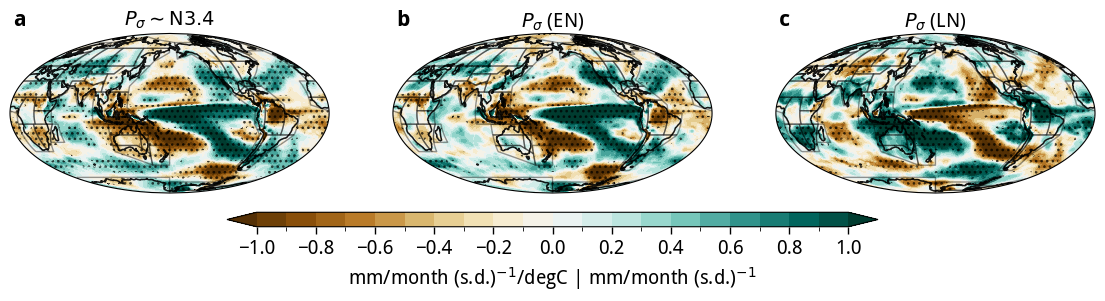

In [ ]:
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
title_list = [
    r'$P_{\sigma} \sim \text{N}3.4$',
    r'$P_{\sigma}$ (EN)',
    r'$P_{\sigma}$ (LN)',
]
label_list = [
    'a', 'b', 'c'
]

plot_maps(xx, yy, plot_list, titles=title_list, labels=label_list, cmap='BrBG', levels=np.linspace(-1.0, 1.0, 21), pval = pval_list, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(14,5), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
            cbar_kwargs=dict(orientation='horizontal', label='mm/month (s.d.)$^{-1}$/degC | mm/month (s.d.)$^{-1}$', aspect=45, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, auto_aspect=False, draw_ipcc_regions=True)

In [47]:
### pr_rean compostites

pr_rean_en   = pr_rean_std.where(cond_nino)
pr_rean_ln   = pr_rean_std.where(cond_nina)
pr_rean_neut = pr_rean_std.where(cond_neut)

In [48]:
# pr_rean_en.to_netcdf("/g/data/if69/as8561/data/enso_tele_robustness/pr_rean_comp_en.nc")
# pr_rean_ln.to_netcdf("/g/data/if69/as8561/data/enso_tele_robustness/pr_rean_comp_ln.nc")
# pr_rean_neut.to_netcdf("/g/data/if69/as8561/data/enso_tele_robustness/pr_rean_comp_neut.nc")

In [50]:
xr.Dataset(dict(en=pr_rean_en, ln=pr_rean_ln, neut=pr_rean_neut)).to_netcdf("/g/data/if69/as8561/data/enso_tele_robustness/pr_rean_composites.nc")

In [39]:
land_mask = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_obs_std)
ar6_mask = regionmask.defined_regions.ar6.land.mask_3D(pr_obs_std.where(land_mask))

In [40]:
land_mask_rean = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_rean_std)
ar6_mask_rean = regionmask.defined_regions.ar6.land.mask_3D(pr_rean_std.where(land_mask_rean))

In [41]:
def calc_tele(precip: xr.DataArray, nino34: xr.DataArray, start_year: int, end_year: int):
    if not isinstance(precip, xr.DataArray) or not isinstance(nino34, xr.DataArray):
        raise TypeError("'xr.DataArray' input is required, not the %s" % (type(precip)))
    duration = end_year - start_year
    res = stats.linregress(nino34.sel(time=slice(str(start_year), str(end_year))), precip.sel(time=slice(str(start_year), str(end_year))))
    return res.slope, res.pvalue, duration


def get_all_tele(precip: xr.DataArray, nino34: xr.DataArray, initial_dur: int = 10):
    if not isinstance(precip, xr.DataArray) or not isinstance(nino34, xr.DataArray):
        raise TypeError("'xr.DataArray' input is required, not the %s" % (type(precip)))
    start_years = np.arange(1900, 2016, 2)
    end_years = np.arange(1900, 2016, 2)
    stat = np.empty((len(start_years), len(end_years)))
    pval = np.empty((len(start_years), len(end_years)))
    duration = np.empty((len(start_years), len(end_years)))
    for i in range(len(start_years)):
        for j in range(len(end_years)):
            if end_years[j] < start_years[i] + initial_dur:
                stat[i, j], pval[i, j], duration[i, j] = np.NaN, np.NaN, np.NaN
            else:
                stat[i, j], pval[i, j], duration[i, j] = calc_tele(precip, nino34, start_years[i], end_years[j])
        # print(f"Completed {start_years[i]}", end='\r')
    return start_years, end_years, stat, pval, duration


In [42]:
pr_obs

<xarray.Dataset> Size: 35MB
Dimensions:  (time: 134, lat: 180, lon: 360)
Coordinates:
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
  * lat      (lat) float64 1kB 89.5 88.5 87.5 86.5 ... -86.5 -87.5 -88.5 -89.5
  * time     (time) object 1kB 1890-06-01 00:00:00 ... 2023-06-01 00:00:00
Data variables:
    pr       (time, lat, lon) float32 35MB dask.array<chunksize=(2, 180, 360), meta=np.ndarray>

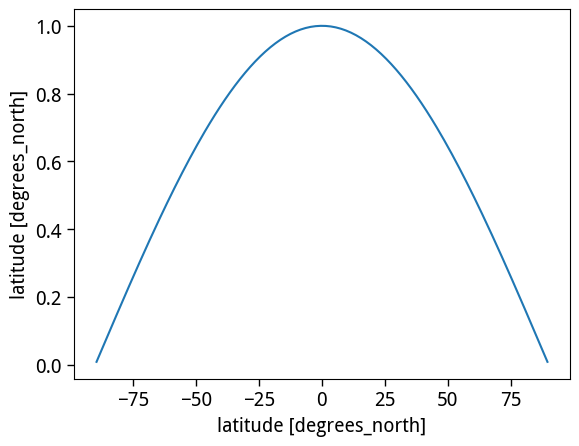

In [43]:
weights_pr_obs = np.cos(np.deg2rad(pr_obs_std.lat))
weights_pr_obs.name = 'weights'
weights_pr_obs.plot()

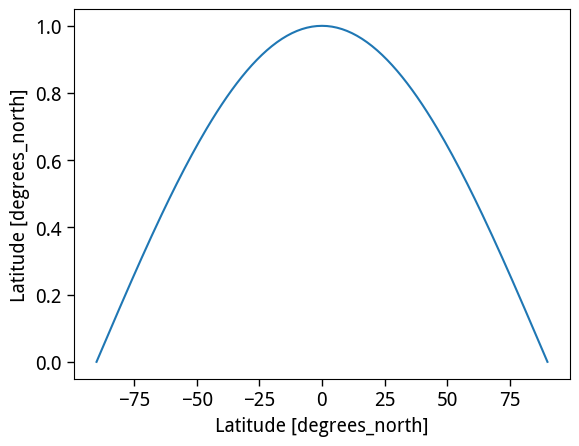

In [44]:
weights_pr_rean = np.cos(np.deg2rad(pr_rean_std.lat))
weights_pr_rean.name = 'weights'
weights_pr_rean.plot()

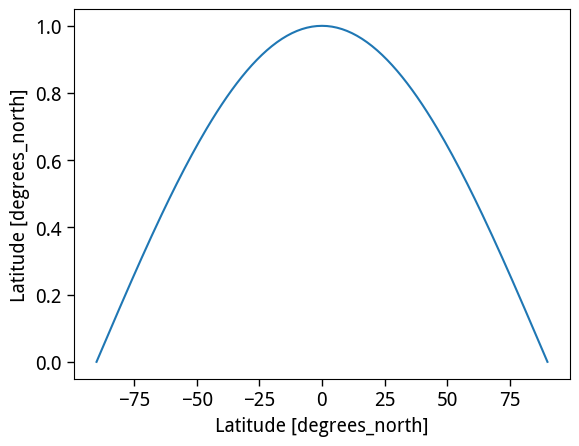

In [45]:
weights_pr_rean = np.cos(np.deg2rad(pr_rean_std.lat))
weights_pr_rean.name = 'weights'
weights_pr_rean.plot()

In [46]:
reg_det = pr_obs_det.where(ar6_mask.isel(region=15), drop=True).weighted(weights_pr_obs).mean(('lat', 'lon'))
reg_std = reg_det/reg_det.std('time')
calc_tele(reg_std, nino34_index_hadisst, start_year=1900, end_year=2014)

(0.051809481870879685, 0.7231260862086714, 114)

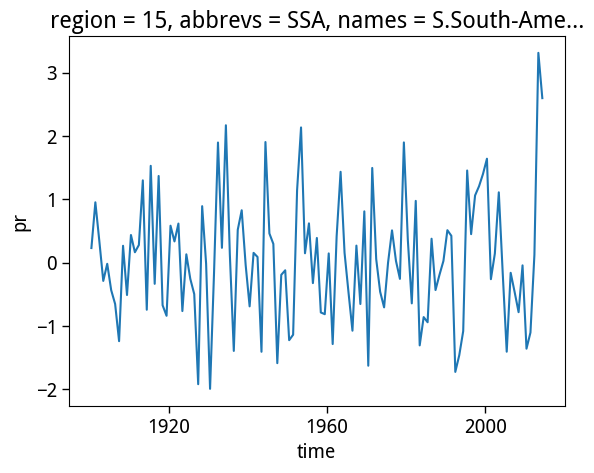

In [47]:
reg_std.plot()

In [48]:
sy, ey, sl, p, dur = get_all_tele(reg_std, nino34_index_hadisst, initial_dur=30)

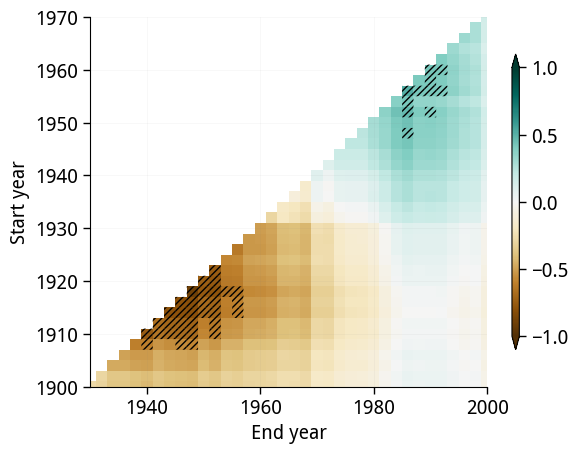

In [49]:
x, y = np.meshgrid(ey, sy)
cf = plt.pcolormesh(ey, sy, sl, cmap='BrBG', vmin=-1.0, vmax=1.0)
z = np.ma.masked_greater(p, 0.05)
plt.pcolor(x,y, z, hatch='/////', alpha=0.)
plt.colorbar(cf, shrink=0.8, extend='both', aspect=40)
# plt.gca().invert_yaxis()
plt.gca().invert_xaxis()
plt.ylabel('Start year')
plt.xlabel('End year')
plt.xlim(1930, 2000)
plt.ylim(1900, 1970)
plot_decorator()
# plt.savefig('./images/method/ssa_reg_temporal_tele_variation.png', dpi=300, bbox_inches='tight')

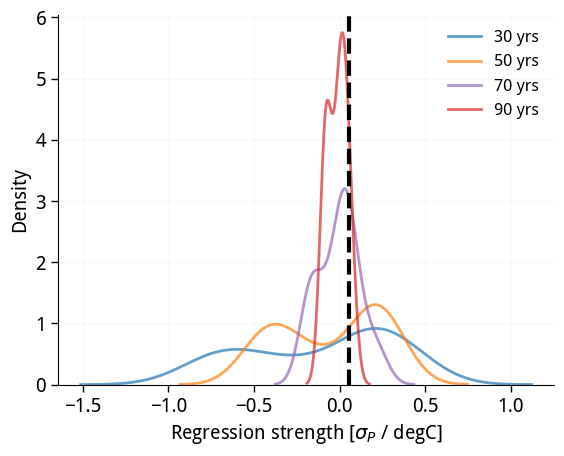

In [50]:
sns.kdeplot(sl[dur==30], alpha=0.7, lw=2.0, color='tab:blue', label='30 yrs')
sns.kdeplot(sl[dur==50], alpha=0.7, lw=2.0, color='tab:orange', label='50 yrs')
sns.kdeplot(sl[dur==70], alpha=0.7, lw=2.0, color='tab:purple', label='70 yrs')
sns.kdeplot(sl[dur==90], alpha=0.7, lw=2.0, color='tab:red', label='90 yrs')
plt.axvline(sl[dur==114], color='k', ls='--', lw=3.0)
plt.legend(frameon=False, fontsize=12)
plt.xlabel('Regression strength [$\sigma_P$ / degC]')
plot_decorator()
# plt.title('N. Australia [OBS]')

# plt.savefig('./images/method/ssa_reg_sample_size_effects.png', dpi=300, bbox_inches='tight')

In [32]:
# def calc_tele_diversity(precip, nino34, duration=30, gap=2):
#     """
#     Code to calculate the regressions and pvalue of a precipaitation and nino34 dataarray in subsequent overallaping 30-year windos
#     separated by a gap of 2 years. Then output a new dataarray with the regression values and pvalues at each gridpoint for the
#     windows with dimensions 'lat', 'lon', and 'ey' where ey is the last-year of the 30 year window
#     """
#     if np.nansum(precip) != 0:
#         i = 0
#         regr_arr = []
#         pval_arr = []
#         ey=[]
#         while i < (len(precip.time) - duration):
#             regr_arr.append(funcs.get_regr(nino34.isel(time = slice(i,i+duration)), precip.isel(time=slice(i,i+duration)), dim='time').data)
#             pval_arr.append(funcs.get_pval(nino34.isel(time = slice(i,i+duration)), precip.isel(time=slice(i,i+duration)), dim='time').data)
#             ey.append(float(nino34.time.dt.year[i+duration]))
#             print(f'Completed ey: {float(nino34.time.dt.year[i+duration])}', end='\r')
#             i += gap

#         out30 = xr.Dataset(
#             data_vars=dict(
#                 regr=(["ey", "lat", "lon"], np.concatenate([arr[np.newaxis, ...] for arr in regr_arr])),
#                 pval=(["ey", "lat", "lon"], np.concatenate([arr[np.newaxis, ...] for arr in pval_arr])),
#             ),
#             coords=dict(
#                 lon = ("lon", precip.lon.to_numpy()),
#                 lat = ("lat", precip.lat.to_numpy()),
#                 ey = ("ey", ey),
#             ),
#             )

#         return out30
    


from tqdm.auto import tqdm


def calc_tele_diversity(field, nino34, duration=30, gap=2, min_years=60):
    """
    Overlapping-window teleconnection across `duration`-year windows.

    A minimum-valid-years guard masks gridpoints where fewer than
    `min_years` finite observations exist, so the noise estimate is
    not computed where the record is too sparse (e.g. Antarctica).

    Returns a Dataset with regr, corr, pval dimensioned (ey, lat, lon),
    plus a `valid_mask` (lat, lon) recording where the estimate is trusted.
    """
    nt      = field.sizes["time"]
    indices = list(range(0, nt - duration, gap))

    regr_list, corr_list, pval_list, ey = [], [], [], []

    for i in tqdm(indices, desc="Overlapping windows"):
        x = nino34.isel(time=slice(i, i + duration))
        y = field.isel(time=slice(i, i + duration))
        slope, corr, pval = funcs.get_all_metrics(x, y, dim="time")
        regr_list.append(slope.data)
        corr_list.append(corr.data)
        pval_list.append(pval.data)
        ey.append(int(nino34.time.dt.year[i + duration]))

    ds = xr.Dataset(
        dict(
            regr=("ey lat lon".split(), np.stack(regr_list)),
            corr=("ey lat lon".split(), np.stack(corr_list)),
            pval=("ey lat lon".split(), np.stack(pval_list)),
        ),
        coords=dict(
            lat=field.lat,
            lon=field.lon,
            ey=("ey", ey),
        ),
    )

    # --- Minimum-valid-years guard ---
    valid_years = np.isfinite(field).sum("time")
    valid_mask  = valid_years >= min_years

    ds = ds.where(valid_mask)
    ds["valid_mask"] = valid_mask
    return ds



# def calc_tele_diversity_winds(wind, nino34, duration=30, gap=2):
#     if np.nansum(wind.uwnd) != 0:
#         i = 0
#         uregr_arr = []
#         vregr_arr = []
#         ey=[]
#         while i < (len(wind.time) - duration):
#             out = funcs.get_regr(nino34.isel(time = slice(i,i+duration)), wind.isel(time=slice(i,i+duration)), dim='time')
#             uregr_arr.append(out.uwnd.data)
#             vregr_arr.append(out.vwnd.data)
#             ey.append(float(nino34.time.dt.year[i+duration]))
#             print(f'Completed ey: {float(nino34.time.dt.year[i+duration])}', end='\r')
#             i += gap

#         out30 = xr.Dataset(
#             data_vars=dict(
#                 uregr=(["ey", "lat", "lon"], np.concatenate([arr[np.newaxis, ...] for arr in uregr_arr])),
#                 vregr=(["ey", "lat", "lon"], np.concatenate([arr[np.newaxis, ...] for arr in vregr_arr])),
#             ),
#             coords=dict(
#                 lon = ("lon", wind.lon.to_numpy()),
#                 lat = ("lat", wind.lat.to_numpy()),
#                 ey = ("ey", ey),
#             ),
#             )

#         return out30

In [49]:
sst_regr_30 = calc_tele_diversity(hadisst_det, nino34_index, duration=30, gap=2)

Overlapping windows:   0%|          | 0/43 [00:00<?, ?it/s]

In [50]:
tas_regr_30 = calc_tele_diversity(tas_obs_det, nino34_index, duration=30, gap=2)

Overlapping windows:   0%|          | 0/43 [00:00<?, ?it/s]

In [51]:
pr_regr_30 = calc_tele_diversity(pr_obs_std, nino34_index, duration=30, gap=2)

Overlapping windows:   0%|          | 0/43 [00:00<?, ?it/s]

In [52]:
pr_regr_30_rean = calc_tele_diversity(pr_rean_std, nino34_index, duration=30, gap=2)

Overlapping windows:   0%|          | 0/43 [00:00<?, ?it/s]

In [ ]:
# psl_regr_30 = calc_tele_diversity(psl_det, nino34_index, duration=30, gap=2)
# uwnd_regr_30 = calc_tele_diversity(uwnd_det, nino34_index, duration=30, gap=2)
# vwnd_regr_30 = calc_tele_diversity(vwnd_det, nino34_index, duration=30, gap=2)
# hgt_regr_30 = calc_tele_diversity(hgt_det, nino34_index, duration=30, gap=2)

Computing teleconnections:   0%|          | 0/43 [00:00<?, ?it/s]

In [55]:
sst_regr_30.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/sst_regr_30.nc')
tas_regr_30.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_30.nc')
pr_regr_30.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30.nc')
pr_regr_30_rean.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30_rean.nc')

In [ ]:
# psl_regr_30.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/psl_regr_30.nc')
# uwnd_regr_30.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/uwnd_regr_30.nc')
# vwnd_regr_30.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/vwnd_regr_30.nc')
# hgt_regr_30.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/hgt_regr_30.nc')

In [28]:
tas_regr_30 = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_30.nc')
pr_regr_30 = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30.nc')
pr_regr_30_rean = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30_rean.nc')

In [33]:
# bootstrapped version of the teleconntcion in plave of overlapping windows


# from scipy import stats
def calc_tele_bootstrap(field, nino34, duration=30, block=3,
                        n_boot=1000, seed=0, min_years=60):
    """
    Block-bootstrap sampling distribution of the `duration`-year
    teleconnection (regression of field on nino34).

    A minimum-valid-years guard masks gridpoints with fewer than
    `min_years` finite observations, preventing the bootstrap-noise
    collapse seen over data-sparse regions (e.g. Antarctica).

    Returns a Dataset with regr, corr, pval dimensioned (window, lat, lon),
    plus a `valid_mask` (lat, lon).
    """
    rng = np.random.default_rng(seed)
    nt  = field.sizes["time"]

    field   = field.transpose("time", "lat", "lon")
    nino_v  = nino34.values
    field_v = field.values

    nlat, nlon = field.sizes["lat"], field.sizes["lon"]
    n_blocks   = int(np.ceil(duration / block))
    max_start  = nt - block
    dof        = duration - 2

    # --- Minimum-valid-years guard (computed once) ---
    valid_count = np.isfinite(field_v).sum(axis=0)          # (lat, lon)
    valid_mask  = valid_count >= min_years

    regr_boot = np.empty((n_boot, nlat, nlon), dtype=float)
    corr_boot = np.empty((n_boot, nlat, nlon), dtype=float)
    pval_boot = np.empty((n_boot, nlat, nlon), dtype=float)

    for b in tqdm(range(n_boot), desc="Bootstrap"):
        starts = rng.integers(0, max_start + 1, size=n_blocks)
        idx    = np.concatenate([np.arange(s, s + block) for s in starts])
        idx    = idx[:duration]

        x = nino_v[idx]
        y = field_v[idx]

        xc = x - x.mean()
        yc = y - y.mean(axis=0, keepdims=True)

        sxx = (xc**2).sum()
        sxy = np.tensordot(xc, yc, axes=([0], [0]))
        syy = (yc**2).sum(axis=0)

        slope = sxy / sxx
        corr  = sxy / np.sqrt(sxx * syy)
        corr  = np.clip(corr, -0.999999, 0.999999)
        t_stat = corr * np.sqrt(dof / (1 - corr**2))
        pval   = 2 * stats.t.sf(np.abs(t_stat), dof)

        regr_boot[b] = slope
        corr_boot[b] = corr
        pval_boot[b] = pval

    ds = xr.Dataset(
        dict(
            regr=(["window", "lat", "lon"], regr_boot),
            corr=(["window", "lat", "lon"], corr_boot),
            pval=(["window", "lat", "lon"], pval_boot),
        ),
        coords=dict(
            lat=field.lat,
            lon=field.lon,
            window=("window", np.arange(n_boot)),
        ),
    )

    # Apply guard
    mask_da = xr.DataArray(valid_mask, dims=["lat", "lon"],
                           coords=dict(lat=field.lat, lon=field.lon))
    ds = ds.where(mask_da)
    ds["valid_mask"] = mask_da
    return ds

In [41]:
sst_regr_boot = calc_tele_bootstrap(hadisst_det, nino34_index, 
                                    duration=30, block=3, n_boot=1000)

Bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

In [42]:
tas_regr_boot = calc_tele_bootstrap(tas_obs_det, nino34_index,
                                    duration=30, block=3, n_boot=1000)


Bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

In [43]:
pr_regr_boot = calc_tele_bootstrap(pr_obs_std, nino34_index, 
                                    duration=30, block=3, n_boot=1000)

Bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

In [44]:
pr_regr_boot_rean = calc_tele_bootstrap(pr_rean_std, nino34_index, 
                                    duration=30, block=3, n_boot=1000)

Bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

In [45]:
tas_regr_boot

<xarray.Dataset> Size: 249MB
Dimensions:     (window: 1000, lat: 72, lon: 144)
Coordinates:
  * lat         (lat) float64 576B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75
  * lon         (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 353.8 356.2 358.8
  * window      (window) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
Data variables:
    regr        (window, lat, lon) float64 83MB nan nan nan ... 0.04708 0.04708
    corr        (window, lat, lon) float64 83MB nan nan nan ... 0.06232 0.06232
    pval        (window, lat, lon) float64 83MB nan nan nan ... 0.7436 0.7436
    valid_mask  (lat, lon) bool 10kB False False False False ... True True True

In [54]:
sst_regr_boot.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/sst_regr_boot.nc')
tas_regr_boot.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_boot.nc')
pr_regr_boot.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_boot.nc')
pr_regr_boot_rean.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_boot_rean.nc')

In [ ]:
# as

In [ ]:
# tas_regr_boot = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_boot.nc')
# pr_regr_boot = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_boot.nc')
# pr_regr_boot_rean = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_boot_rean.nc')

In [56]:
def compare_noise_spatial(noise_sets):
    """
    noise_sets: list of (label, roll_da, boot_da), each (lat, lon).
    Plots overlapping, bootstrap, and ratio (boot/roll) per row.
    """
    nrows = len(noise_sets)
    fig, axes = plt.subplots(
        nrows, 3, figsize=(16, 3*nrows),
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180))
    )
    if nrows == 1:
        axes = axes[np.newaxis, :]

    for r, (label, roll, boot) in enumerate(noise_sets):

        vmax = float(max(np.nanpercentile(roll, 95),
                         np.nanpercentile(boot, 95)))
        ratio = boot / roll

        # Overlapping
        im0 = axes[r,0].pcolormesh(roll.lon, roll.lat, roll.values,
                                   transform=ccrs.PlateCarree(),
                                   cmap='viridis', vmin=0, vmax=vmax,
                                   shading='auto')
        plt.colorbar(im0, ax=axes[r,0], fraction=0.025, pad=0.02)
        axes[r,0].set_title(f'{label} — Overlapping')
        axes[r,0].coastlines(lw=0.5)

        # Bootstrap
        im1 = axes[r,1].pcolormesh(boot.lon, boot.lat, boot.values,
                                   transform=ccrs.PlateCarree(),
                                   cmap='viridis', vmin=0, vmax=vmax,
                                   shading='auto')
        plt.colorbar(im1, ax=axes[r,1], fraction=0.025, pad=0.02)
        axes[r,1].set_title(f'{label} — Bootstrap')
        axes[r,1].coastlines(lw=0.5)

        # Ratio
        im2 = axes[r,2].pcolormesh(ratio.lon, ratio.lat, ratio.values,
                                   transform=ccrs.PlateCarree(),
                                   cmap='RdBu_r', vmin=0.5, vmax=1.5,
                                   shading='auto')
        plt.colorbar(im2, ax=axes[r,2], fraction=0.025, pad=0.02)
        axes[r,2].set_title(f'{label} — Ratio (boot/roll)')
        axes[r,2].coastlines(lw=0.5)

    plt.tight_layout()
    # return fig



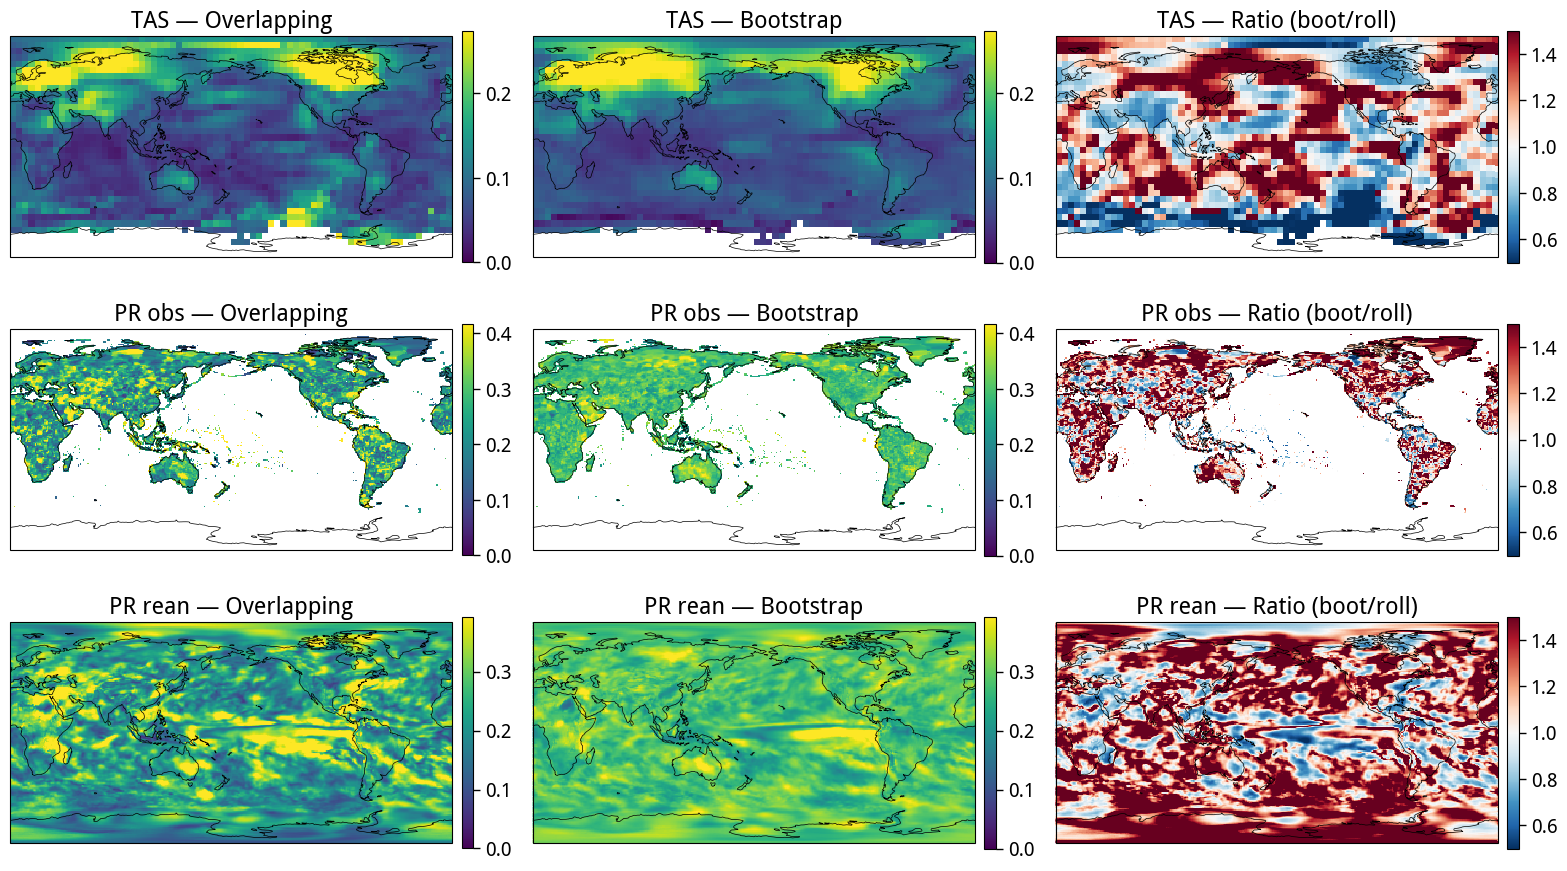

In [57]:
noise_sets = [
    ('TAS',     tas_regr_30.regr.std('ey'),   tas_regr_boot.regr.std('window')),
    ('PR obs',  pr_regr_30.regr.std('ey'),    pr_regr_boot.regr.std('window')),
    ('PR rean', pr_regr_30_rean.regr.std('ey'),    pr_regr_boot_rean.regr.std('window')),
]
compare_noise_spatial(noise_sets)

In [58]:

noise_rolling = tas_regr_30.regr.std('ey')
noise_boot = tas_regr_boot.regr.std('window')

ratio_tas = noise_boot/noise_rolling


print("Ratio (bootstrap / rolling) statistics:")
print(f"  Median: {float(ratio_tas.median()):.3f}")
print(f"  Mean:   {float(ratio_tas.mean()):.3f}")
print(f"  5–95%:  {float(ratio_tas.quantile(0.05)):.3f} to {float(ratio_tas.quantile(0.95)):.3f}")

Ratio (bootstrap / rolling) statistics:
  Median: 1.044
  Mean:   1.106
  5–95%:  0.462 to 1.916


<function __main__.plot_decorator()>

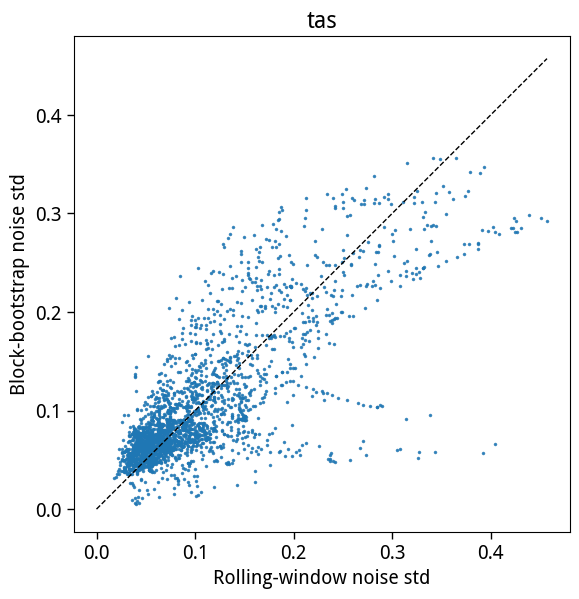

In [59]:

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(noise_rolling.values.ravel(),
           noise_boot.values.ravel(),
           s=2, alpha=0.3)
lim = [0, float(max(noise_rolling.max(), noise_boot.max()))]
ax.plot(lim, lim, 'k--', lw=1)   # 1:1 line
ax.set_xlabel('Rolling-window noise std')
ax.set_ylabel('Block-bootstrap noise std')
ax.set_aspect('equal')
plt.tight_layout()
plt.title('tas')
plot_decorator

In [60]:

noise_rolling = pr_regr_30.regr.std('ey')
noise_boot = pr_regr_boot.regr.std('window')

ratio_pr_obs = noise_boot/noise_rolling


print("Ratio (bootstrap / rolling) statistics:")
print(f"  Median: {float(ratio_pr_obs.median()):.3f}")
print(f"  Mean:   {float(ratio_pr_obs.mean()):.3f}")
print(f"  5–95%:  {float(ratio_pr_obs.quantile(0.05)):.3f} to {float(ratio_pr_obs.quantile(0.95)):.3f}")


Ratio (bootstrap / rolling) statistics:
  Median: 1.228
  Mean:   1.315
  5–95%:  0.731 to 2.194


<function __main__.plot_decorator()>

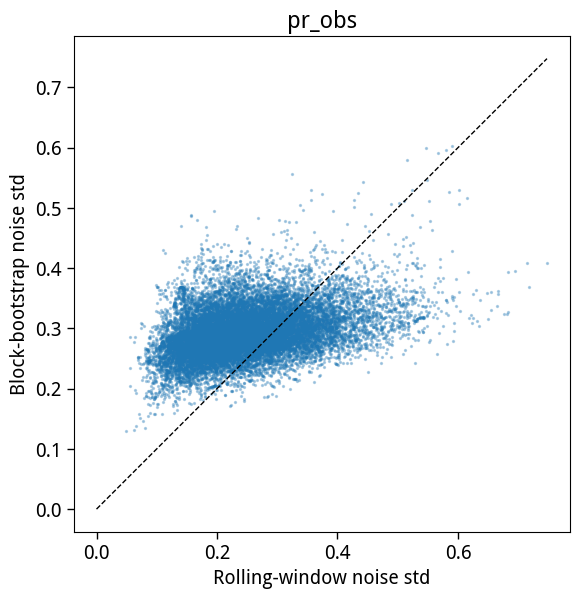

In [61]:

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(noise_rolling.values.ravel(),
           noise_boot.values.ravel(),
           s=2, alpha=0.3)
lim = [0, float(max(noise_rolling.max(), noise_boot.max()))]
ax.plot(lim, lim, 'k--', lw=1)   # 1:1 line
ax.set_xlabel('Rolling-window noise std')
ax.set_ylabel('Block-bootstrap noise std')
ax.set_aspect('equal')
plt.tight_layout()
plt.title('pr_obs')
plot_decorator

In [62]:

noise_rolling = pr_regr_30_rean.regr.std('ey')
noise_boot = pr_regr_boot_rean.regr.std('window')

ratio_pr_rean = noise_boot/noise_rolling


print("Ratio (bootstrap / rolling) statistics:")
print(f"  Median: {float(ratio_pr_rean.median()):.3f}")
print(f"  Mean:   {float(ratio_pr_rean.mean()):.3f}")
print(f"  5–95%:  {float(ratio_pr_rean.quantile(0.05)):.3f} to {float(ratio_pr_rean.quantile(0.95)):.3f}")

Ratio (bootstrap / rolling) statistics:
  Median: 1.256
  Mean:   1.338
  5–95%:  0.760 to 2.216


<function __main__.plot_decorator()>

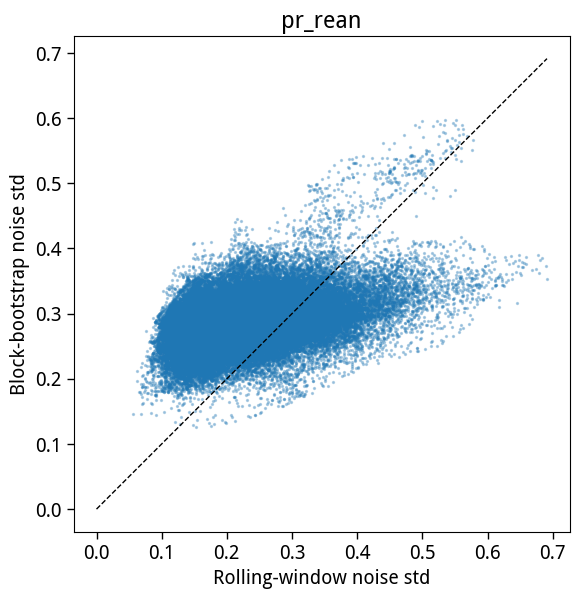

In [63]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(noise_rolling.values.ravel(),
           noise_boot.values.ravel(),
           s=2, alpha=0.3)
lim = [0, float(max(noise_rolling.max(), noise_boot.max()))]
ax.plot(lim, lim, 'k--', lw=1)   # 1:1 line
ax.set_xlabel('Rolling-window noise std')
ax.set_ylabel('Block-bootstrap noise std')
ax.set_aspect('equal')
plt.tight_layout()
plt.title('pr_rean')
plot_decorator

In [64]:
for blk in [2, 3, 4, 5]:
    boot = calc_tele_bootstrap(pr_rean_std, nino34_index,
                               duration=30, block=blk, n_boot=1000)
    nb = boot.regr.std('window')
    print(f"block={blk}: grid-mean noise = {float(nb.mean()):.4f}")

Bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

block=2: grid-mean noise = 0.2919


Bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

block=3: grid-mean noise = 0.2882


Bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

block=4: grid-mean noise = 0.2849


Bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

block=5: grid-mean noise = 0.2832


Text(0.5, 1.0, 'Gridpoints where bootstrap noise < rolling noise')

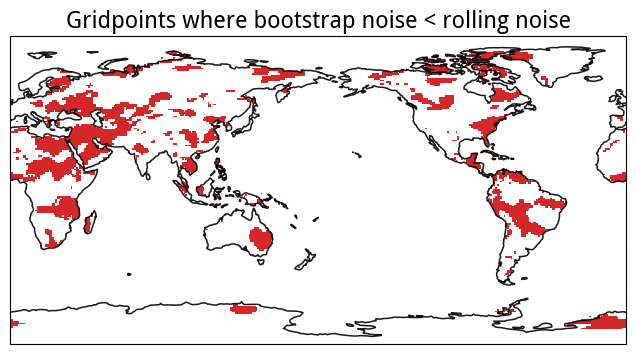

In [66]:
from matplotlib import colors as mcolors

land_2d = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(
    ratio_pr_rean
).any('region')

below_field = xr.where((ratio_pr_rean < 1.0) & land_2d, 1.0, np.nan)

fig, ax = plt.subplots(figsize=(10, 4),
                       subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180)))

ax.pcolormesh(below_field.lon, below_field.lat, below_field.values,
              transform=ccrs.PlateCarree(),
              cmap=mcolors.ListedColormap(['tab:red']),
              vmin=0, vmax=1, shading='auto')
plot_background(ax)
ax.set_title('Gridpoints where bootstrap noise < rolling noise')

Text(0.5, 1.0, 'Gridpoints where bootstrap noise < rolling noise')

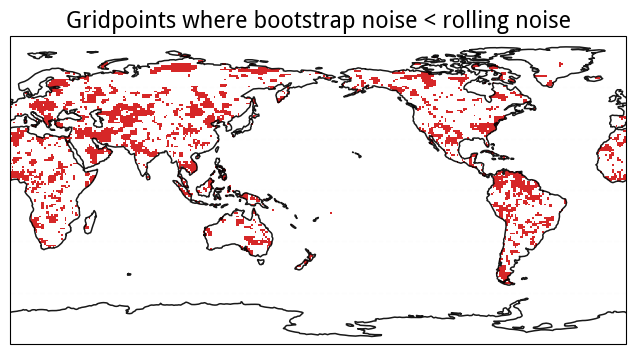

In [69]:
from matplotlib import colors as mcolors

land_2d = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(
    ratio_pr_obs
).any('region')

below_field = xr.where((ratio_pr_obs < 1.0) & land_2d, 1.0, np.nan)

fig, ax = plt.subplots(figsize=(10, 4),
                       subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180)))

ax.pcolormesh(below_field.lon, below_field.lat, below_field.values,
              transform=ccrs.PlateCarree(),
              cmap=mcolors.ListedColormap(['tab:red']),
              vmin=0, vmax=1, shading='auto')
plot_background(ax)
ax.set_title('Gridpoints where bootstrap noise < rolling noise')

Text(0.5, 1.0, 'Gridpoints where bootstrap noise < rolling noise')

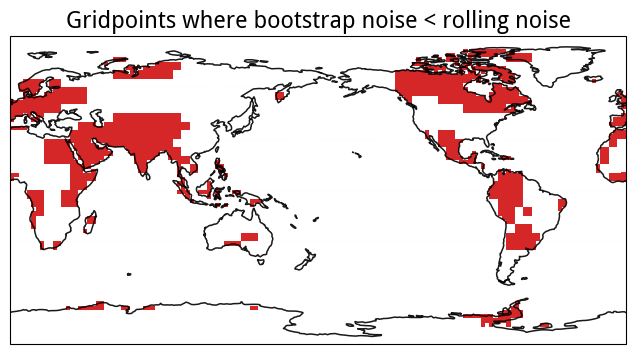

In [70]:
from matplotlib import colors as mcolors

land_2d = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(
    ratio_tas
).any('region')

below_field = xr.where((ratio_tas < 1.0) & land_2d, 1.0, np.nan)

fig, ax = plt.subplots(figsize=(10, 4),
                       subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180)))

ax.pcolormesh(below_field.lon, below_field.lat, below_field.values,
              transform=ccrs.PlateCarree(),
              cmap=mcolors.ListedColormap(['tab:red']),
              vmin=0, vmax=1, shading='auto')
plot_background(ax)
ax.set_title('Gridpoints where bootstrap noise < rolling noise')

In [ ]:
plot_list = [
    tas_regr,
    tas_regr_30.regr.min('ey'),
    tas_regr_30.regr.max('ey'),
]

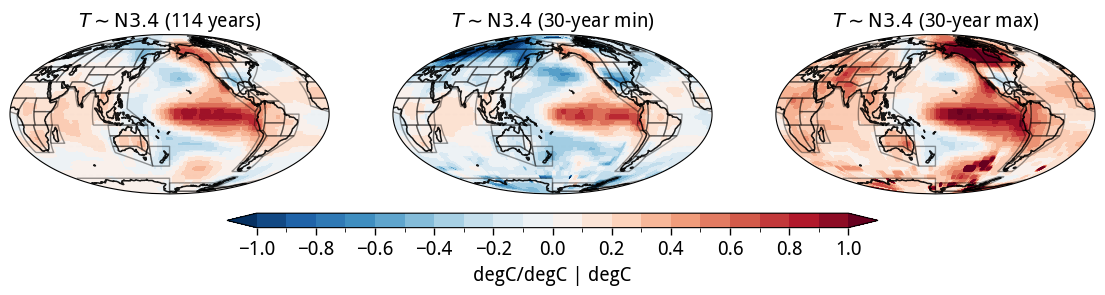

In [ ]:
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
title_list = [
    r'$T \sim \text{N}3.4$ (114 years)',
    r'$T \sim \text{N}3.4$ (30-year min)',
    r'$T \sim \text{N}3.4$ (30-year max)',
]

plot_maps(xx, yy, plot_list, titles=title_list, labels=['']*3, cmap='RdBu_r', levels=np.linspace(-1.0, 1.0, 21), pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(14,5), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
            cbar_kwargs=dict(orientation='horizontal', label='degC/degC | degC', aspect=45, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, auto_aspect=False, draw_ipcc_regions=True)

In [38]:
plot_list = [
    pr_regr,
    pr_regr_30.regr.min('ey'),
    pr_regr_30.regr.max('ey'),
]

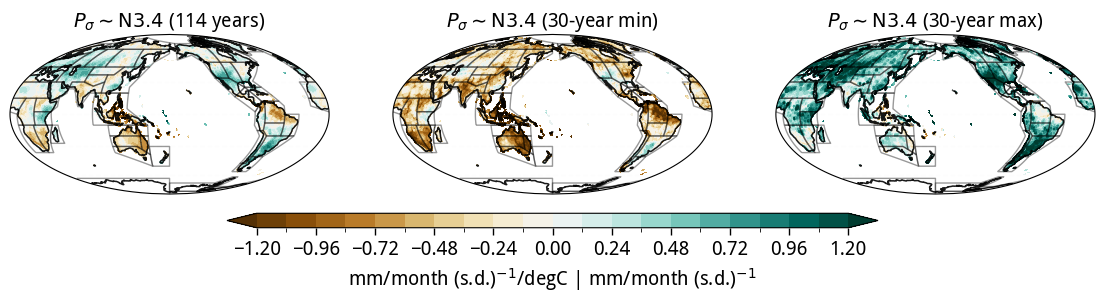

In [39]:
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
title_list = [
    r'$P_{\sigma} \sim \text{N}3.4$ (114 years)',
    r'$P_{\sigma} \sim \text{N}3.4$ (30-year min)',
    r'$P_{\sigma} \sim \text{N}3.4$ (30-year max)',
]

plot_maps(xx, yy, plot_list, titles=title_list, labels=['']*3, cmap='BrBG', levels=np.linspace(-1.2, 1.2, 21), pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(14,5), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
            cbar_kwargs=dict(orientation='horizontal', label='mm/month (s.d.)$^{-1}$/degC | mm/month (s.d.)$^{-1}$', aspect=45, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, auto_aspect=False, draw_ipcc_regions=True)

In [40]:
plot_list = [
    pr_regr_rean,
    pr_regr_30_rean.regr.min('ey'),
    pr_regr_30_rean.regr.max('ey'),
]

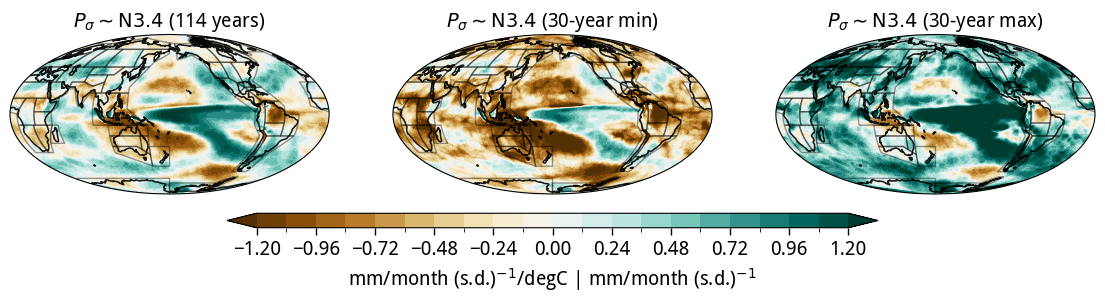

In [41]:
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
title_list = [
    r'$P_{\sigma} \sim \text{N}3.4$ (114 years)',
    r'$P_{\sigma} \sim \text{N}3.4$ (30-year min)',
    r'$P_{\sigma} \sim \text{N}3.4$ (30-year max)',
]

plot_maps(xx, yy, plot_list, titles=title_list, labels=['']*3, cmap='BrBG', levels=np.linspace(-1.2, 1.2, 21), pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(14,5), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
            cbar_kwargs=dict(orientation='horizontal', label='mm/month (s.d.)$^{-1}$/degC | mm/month (s.d.)$^{-1}$', aspect=45, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, auto_aspect=False, draw_ipcc_regions=True)

In [42]:
# tas_regr_30.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_30.nc')
# pr_regr_30.to_netcdf('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30.nc')

In [39]:
plot_list = [
    (tas_regr_30.pval.where(tas_regr_30.pval < 0.05).count('ey')/tas_regr_30.pval.count('ey')),
    (pr_regr_30.pval.where(pr_regr_30.pval < 0.05).count('ey')/pr_regr_30.pval.count('ey')),
    (pr_regr_30_rean.pval.where(pr_regr_30_rean.pval < 0.05).count('ey')/pr_regr_30_rean.pval.count('ey')),
]

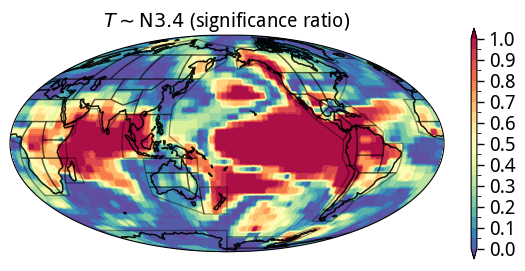

In [68]:
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
title_list = [
    r'$T \sim \text{N}3.4$ (significance ratio)',
    r'$P_{\sigma} \sim \text{N}3.4$ (significance ratio)',
]

plot_single_map(xx, yy, plot_list[0], title_list[0], label='', cmap='Spectral_r', levels=np.linspace(0, 1.0, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

In [59]:
import xesmf as xe

In [63]:
regridder = xe.Regridder(plot_list[1], plot_list[2], method='bilinear')

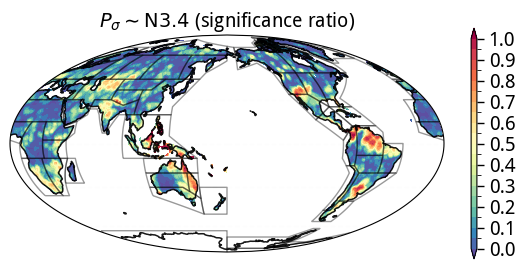

In [ ]:
xx, yy = np.meshgrid(plot_list[2].lon, plot_list[2].lat)

plot_single_map(xx, yy, regridder(plot_list[1]), title_list[1], label='', cmap='Spectral_r', levels=np.linspace(0, 1.0, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

# ax = plt.axes(projection=ccrs.Mollweide(central_longitude=180))
# cf = plt.contourf(xx, yy, plot_list[1], transform=ccrs.PlateCarree(), cmap='Spectral_r', levels=np.linspace(0, 1.0, 21))
# plt.colorbar(cf)
# plot_background(ax)

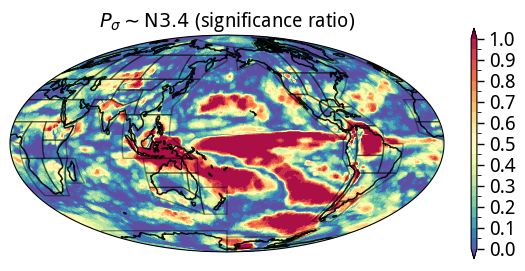

In [69]:
xx, yy = np.meshgrid(plot_list[2].lon, plot_list[2].lat)

plot_single_map(xx, yy, plot_list[2], title_list[1], label='', cmap='Spectral_r', levels=np.linspace(0, 1.0, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

In [81]:
tpi = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/tpi.nc').resample(time = '1Y').mean('time')
tpi

<xarray.Dataset> Size: 4kB
Dimensions:    (time: 155)
Coordinates:
  * time       (time) datetime64[ns] 1kB 1870-12-31 1871-12-31 ... 2024-12-31
Data variables:
    TPI_fil    (time) float64 1kB nan nan nan nan nan ... nan nan nan nan nan
    TPI_unfil  (time) float64 1kB -0.7167 -0.222 -0.6505 ... -0.01458 0.221

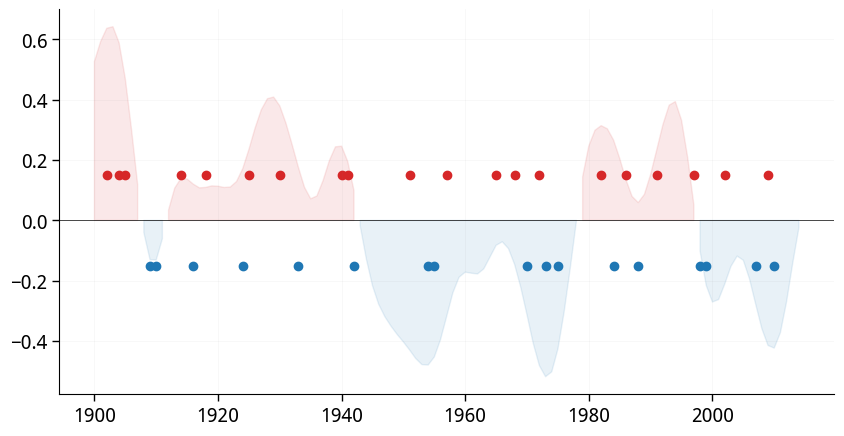

In [89]:
plt.figure(figsize=(10,5))
xdata = tpi.sel(time = slice('1900', '2014')).time.dt.year
plt.fill_between(xdata, 0, tpi.sel(time = slice('1900', '2014')).TPI_fil.where(tpi.TPI_fil > 0), color='tab:red', alpha=0.1)
plt.fill_between(xdata, 0, tpi.sel(time = slice('1900', '2014')).TPI_fil.where(tpi.TPI_fil < 0), color='tab:blue', alpha=0.1)

xdata = nino34_index.time.dt.year
plt.scatter(xdata.where(nino34_index > nino34_index.std('time')), nino34_index.where(nino34_index > nino34_index.std('time'))*0 + 0.15, color='tab:red')
plt.scatter(xdata.where(nino34_index < -nino34_index.std('time')), nino34_index.where(nino34_index < -nino34_index.std('time'))*0 - 0.15, color='tab:blue')

plot_decorator()
plt.axhline(0.0, color='k', lw=0.5)

In [83]:
def calc_windowed_index_strength(index_time_series, duration=30, gap=2, std=False):
    if np.nansum(index_time_series) != 0:
        i = 0
        index_out = []
        ey=[]
        while i < (len(index_time_series.time) - duration):
            if std==False:
                index_out.append(index_time_series.isel(time=slice(i,i+duration)).mean('time').data)
            else:
                index_out.append(index_time_series.isel(time=slice(i,i+duration)).std('time').data)
            ey.append(float(index_time_series.time.dt.year[i+duration]))
            print(f'Completed ey: {float(index_time_series.time.dt.year[i+duration])}', end='\r')
            i += gap

        out = xr.Dataset(
            data_vars=dict(
                index=(["ey"], np.concatenate([arr[np.newaxis, ...] for arr in index_out])),
            ),
            coords=dict(
                ey = ("ey", ey),
            ),
            )

        return out

In [84]:
tpi_windows = calc_windowed_index_strength(tpi.TPI_unfil.resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')), duration=30, gap=2)

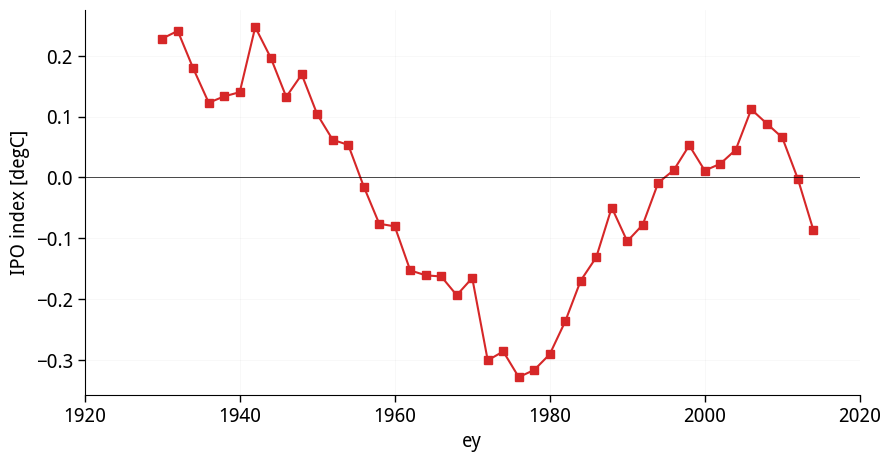

In [92]:
plt.figure(figsize=(10,5))
# (tpi_da.TPI_unfil).resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')).plot(color='k', alpha=0.1, lw=1.0)
# (tpi_da.TPI_fil).resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')).plot(lw=2.0, color='tab:red')
(tpi_windows.index).plot(marker='s', color='tab:red')
plt.axhline(0.0, color='k', lw=0.5)
plt.ylabel('IPO index [degC]')
plt.xlim(1920, 2020)
plot_decorator()

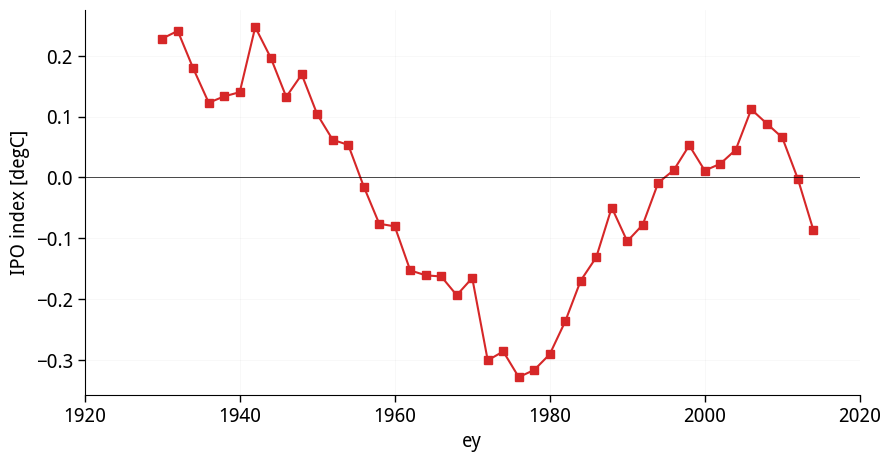

In [ ]:
plt.figure(figsize=(10,5))
# (tpi_da.TPI_unfil).resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')).plot(color='k', alpha=0.1, lw=1.0)
# (tpi_da.TPI_fil).resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')).plot(lw=2.0, color='tab:red')
(tpi_windows.index).plot(marker='s', color='tab:red')
plt.axhline(0.0, color='k', lw=0.5)
plt.ylabel('IPO index [degC]')
plt.xlim(1920, 2020)
plot_decorator()

In [120]:


ipo_pos = tas_regr_30.regr.where(tpi_windows.index > tpi_windows.index.std('ey'), drop=True).mean('ey')
ipo_neg = tas_regr_30.regr.where(tpi_windows.index < -tpi_windows.index.std('ey'), drop=True).mean('ey')
plot_list = [
    ipo_pos,
    ipo_neg,
]

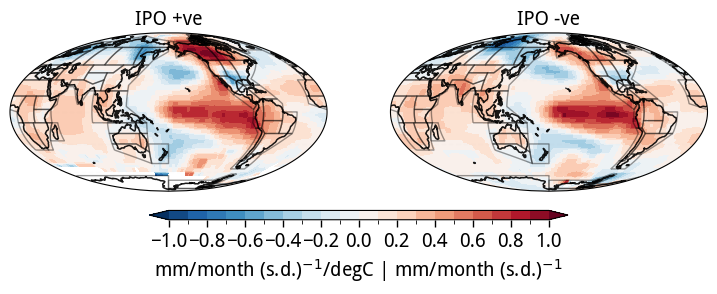

In [121]:
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
title_list = [
    r'IPO +ve',
    r'IPO -ve',
]

plot_maps(xx, yy, plot_list, titles=title_list, labels=['']*3, cmap='RdBu_r', levels=np.linspace(-1., 1., 21), pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=2, figsize=(9,5), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
            cbar_kwargs=dict(orientation='horizontal', label='mm/month (s.d.)$^{-1}$/degC | mm/month (s.d.)$^{-1}$', aspect=45, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, auto_aspect=False, draw_ipcc_regions=True)

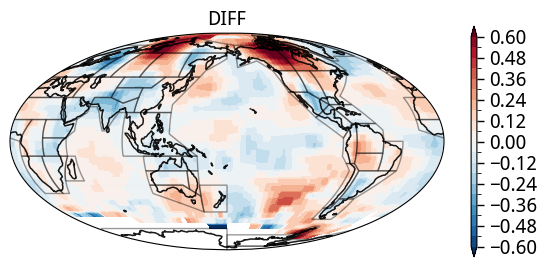

In [124]:
zz = ipo_pos - ipo_neg
plot_single_map(xx, yy, zz, title='DIFF', label='', cmap='RdBu_r', levels=np.linspace(-0.6, 0.6, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

In [125]:


ipo_pos = pr_regr_30.regr.where(tpi_windows.index > tpi_windows.index.std('ey'), drop=True).mean('ey')
ipo_neg = pr_regr_30.regr.where(tpi_windows.index < -tpi_windows.index.std('ey'), drop=True).mean('ey')
plot_list = [
    ipo_pos,
    ipo_neg,
]

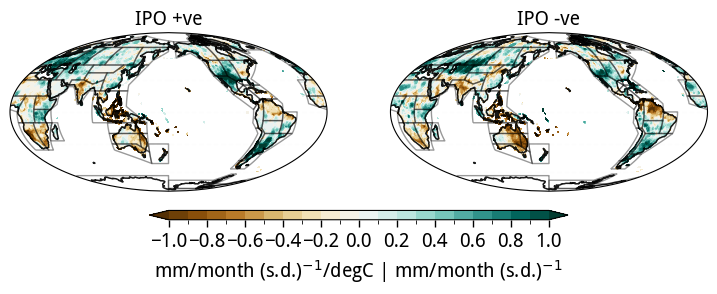

In [126]:
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
title_list = [
    r'IPO +ve',
    r'IPO -ve',
]

plot_maps(xx, yy, plot_list, titles=title_list, labels=['']*3, cmap='BrBG', levels=np.linspace(-1., 1., 21), pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=2, figsize=(9,5), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
            cbar_kwargs=dict(orientation='horizontal', label='mm/month (s.d.)$^{-1}$/degC | mm/month (s.d.)$^{-1}$', aspect=45, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, auto_aspect=False, draw_ipcc_regions=True)

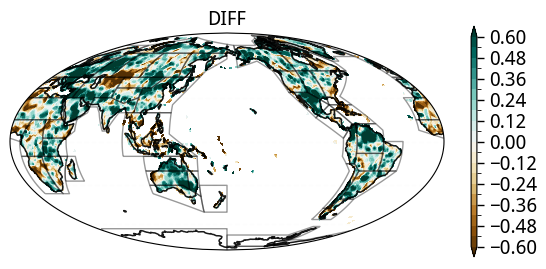

In [127]:
zz = ipo_pos - ipo_neg
plot_single_map(xx, yy, zz, title='DIFF', label='', cmap='BrBG', levels=np.linspace(-0.6, 0.6, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

In [128]:


ipo_pos = pr_regr_30_rean.regr.where(tpi_windows.index > tpi_windows.index.std('ey'), drop=True).mean('ey')
ipo_neg = pr_regr_30_rean.regr.where(tpi_windows.index < -tpi_windows.index.std('ey'), drop=True).mean('ey')
plot_list = [
    ipo_pos,
    ipo_neg,
]

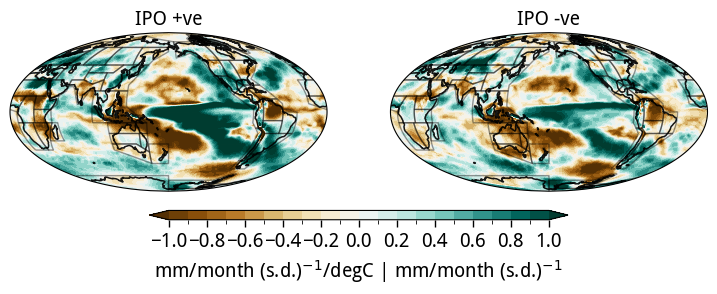

In [129]:
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
title_list = [
    r'IPO +ve',
    r'IPO -ve',
]

plot_maps(xx, yy, plot_list, titles=title_list, labels=['']*3, cmap='BrBG', levels=np.linspace(-1., 1., 21), pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=2, figsize=(9,5), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
            cbar_kwargs=dict(orientation='horizontal', label='mm/month (s.d.)$^{-1}$/degC | mm/month (s.d.)$^{-1}$', aspect=45, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, auto_aspect=False, draw_ipcc_regions=True)

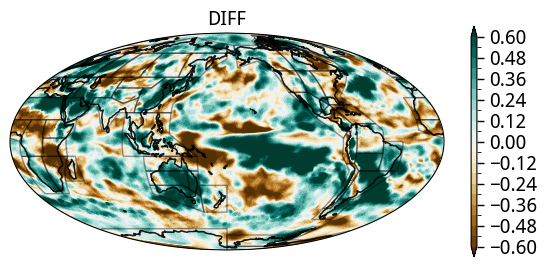

In [130]:
zz = ipo_pos - ipo_neg
plot_single_map(xx, yy, zz, title='DIFF', label='', cmap='BrBG', levels=np.linspace(-0.6, 0.6, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Mollweide(central_longitude=180), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)